# Notebook 05 — Evaluation

## Objective
Evaluate model predictions consistently and compare forecasting performance.

## What Evaluation Involves
- Generate predictions on held-out data.
- Compare predictions against the ground-truth targets.
- Calculate MAE, RMSE, and MAPE.
- Compare models using the same evaluation procedure.
- Inspect additional breakdowns where implemented.

## Metrics

### MAE
Measures the average absolute difference between predictions and actual values.

### RMSE
Measures the square root of the average squared prediction error. Larger errors receive greater weight.

### MAPE
Measures prediction error relative to actual values as a percentage. It can become unstable when actual values are zero or close to zero.

## Data Splits
- Training set: used to fit model parameters.
- Validation set: used for model selection and configuration decisions.
- Test set: used for final evaluation.

## Important Principle
Models should only be compared fairly when they use compatible data splits, target scales, metric implementations, and evaluation samples.

## Review Reminder
Be prepared to explain:
- Why a separate test set is necessary.
- Why validation data is used during model development.
- Why lower error metrics are generally preferred.
- Why metrics alone may not explain model behaviour.

# Phase 5: Comprehensive Evaluation

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path("/content")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed" / "METR-LA"

print("Project root:", PROJECT_ROOT)
print("Processed directory:", PROCESSED_DIR)

Project root: /content
Processed directory: /content/data/processed/METR-LA


In [2]:
train_data = np.load(PROCESSED_DIR / "train.npz")
val_data = np.load(PROCESSED_DIR / "val.npz")
test_data = np.load(PROCESSED_DIR / "test.npz")

print("Train keys:", train_data.files)
print("Validation keys:", val_data.files)
print("Test keys:", test_data.files)

Train keys: ['X', 'Y']
Validation keys: ['X', 'Y']
Test keys: ['X', 'Y']


In [4]:
X_train = train_data["X"]
Y_train = train_data["Y"]

X_val = val_data["X"]
Y_val = val_data["Y"]

X_test = test_data["X"]
Y_test = test_data["Y"]

print("X_train:", X_train.shape)
print("Y_train:", Y_train.shape)
print("X_val:", X_val.shape)
print("Y_val:", Y_val.shape)
print("X_test:", X_test.shape)
print("Y_test:", Y_test.shape)

X_train: (23976, 12, 207, 1)
Y_train: (23976, 3, 207, 1)
X_val: (3413, 12, 207, 1)
Y_val: (3413, 3, 207, 1)
X_test: (6841, 12, 207, 1)
Y_test: (6841, 3, 207, 1)


In [5]:
scaler_data = np.load(PROCESSED_DIR / "scaler.npz")

print("Scaler keys:", scaler_data.files)

for key in scaler_data.files:
    print(key, scaler_data[key].shape)

Scaler keys: ['mean', 'std']
mean (207,)
std (207,)


In [6]:
def inverse_transform(data, mean, std):
    """
    Convert standardized traffic values back to original speed scale.

    data: (N, time, nodes, 1)
    mean: (207,)
    std:  (207,)
    """
    data = np.asarray(data)

    mean = mean.reshape(1, 1, -1, 1)
    std = std.reshape(1, 1, -1, 1)

    return data * std + mean

In [7]:
Y_test_original = inverse_transform(
    Y_test,
    scaler_data["mean"],
    scaler_data["std"]
)

print("Original-scale shape:", Y_test_original.shape)
print("Minimum speed:", Y_test_original.min())
print("Maximum speed:", Y_test_original.max())
print("Mean speed:", Y_test_original.mean())

Original-scale shape: (6841, 3, 207, 1)
Minimum speed: -3.8146973e-06
Maximum speed: 70.0
Mean speed: 50.753143


In [9]:
from pathlib import Path
import numpy as np

PREDICTIONS_DIR = Path("/content/experiments/stgcn")

stgcn_y_pred = np.load(
    PREDICTIONS_DIR / "test_predictions.npy"
)

stgcn_y_true = np.load(
    PREDICTIONS_DIR / "test_targets.npy"
)

print("STGCN predictions:", stgcn_y_pred.shape)
print("STGCN targets:", stgcn_y_true.shape)

STGCN predictions: (6841, 3, 207, 1)
STGCN targets: (6841, 3, 207, 1)


In [10]:
stgcn_pred_original = inverse_transform(
    stgcn_y_pred,
    scaler_data["mean"],
    scaler_data["std"]
)

stgcn_true_original = inverse_transform(
    stgcn_y_true,
    scaler_data["mean"],
    scaler_data["std"]
)

print("Prediction shape:", stgcn_pred_original.shape)
print("Target shape:", stgcn_true_original.shape)

print("Prediction range:",
      stgcn_pred_original.min(),
      "to",
      stgcn_pred_original.max())

print("Target range:",
      stgcn_true_original.min(),
      "to",
      stgcn_true_original.max())

Prediction shape: (6841, 3, 207, 1)
Target shape: (6841, 3, 207, 1)
Prediction range: -37.190998 to 75.755875
Target range: -3.8146973e-06 to 70.0


In [12]:
def mae(y_true, y_pred):
    return float(np.mean(np.abs(y_true - y_pred)))


def rmse(y_true, y_pred):
    return float(np.sqrt(np.mean((y_true - y_pred) ** 2)))


def mape(y_true, y_pred, epsilon=1e-5):
    mask = np.abs(y_true) > epsilon

    if not np.any(mask):
        return float("nan")

    return float(
        np.mean(
            np.abs(
                (y_true[mask] - y_pred[mask]) / y_true[mask]
            )
        ) * 100
    )


def evaluate_predictions(y_true, y_pred):
    return {
        "MAE": mae(y_true, y_pred),
        "RMSE": rmse(y_true, y_pred),
        "MAPE": mape(y_true, y_pred),
    }

In [13]:
stgcn_original_results = evaluate_predictions(
    stgcn_true_original,
    stgcn_pred_original
)

print("STGCN — Original Speed Scale")
for metric, value in stgcn_original_results.items():
    print(f"{metric}: {value:.6f}")

STGCN — Original Speed Scale
MAE: 6.263297
RMSE: 11.017338
MAPE: 13.161572


In [14]:
horizon_results = []

for horizon_idx, horizon_minutes in enumerate([5, 10, 15]):
    y_true_h = stgcn_true_original[:, horizon_idx, :, :]
    y_pred_h = stgcn_pred_original[:, horizon_idx, :, :]

    metrics = evaluate_predictions(y_true_h, y_pred_h)

    horizon_results.append({
        "Horizon": f"{horizon_minutes} min",
        "MAE": metrics["MAE"],
        "RMSE": metrics["RMSE"],
        "MAPE": metrics["MAPE"],
    })

horizon_df = pd.DataFrame(horizon_results)

horizon_df

,Horizon,MAE,RMSE,MAPE
0,5 min,5.875838,10.208804,12.432792
1,10 min,6.270047,11.027397,13.169551
2,15 min,6.644026,11.761041,13.882375


In [15]:
EVALUATION_DIR = Path("/content/experiments/stgcn")
EVALUATION_DIR.mkdir(parents=True, exist_ok=True)

horizon_df.to_csv(
    EVALUATION_DIR / "horizon_results.csv",
    index=False
)

pd.DataFrame([stgcn_original_results]).to_csv(
    EVALUATION_DIR / "overall_results.csv",
    index=False
)

print("Saved evaluation results:")
print(EVALUATION_DIR / "horizon_results.csv")
print(EVALUATION_DIR / "overall_results.csv")

Saved evaluation results:
/content/experiments/stgcn/horizon_results.csv
/content/experiments/stgcn/overall_results.csv


In [16]:
SENSOR_INDEX = 0
NUM_SAMPLES_TO_PLOT = 100

print("Sensor:", SENSOR_INDEX)
print("Samples:", NUM_SAMPLES_TO_PLOT)

Sensor: 0
Samples: 100


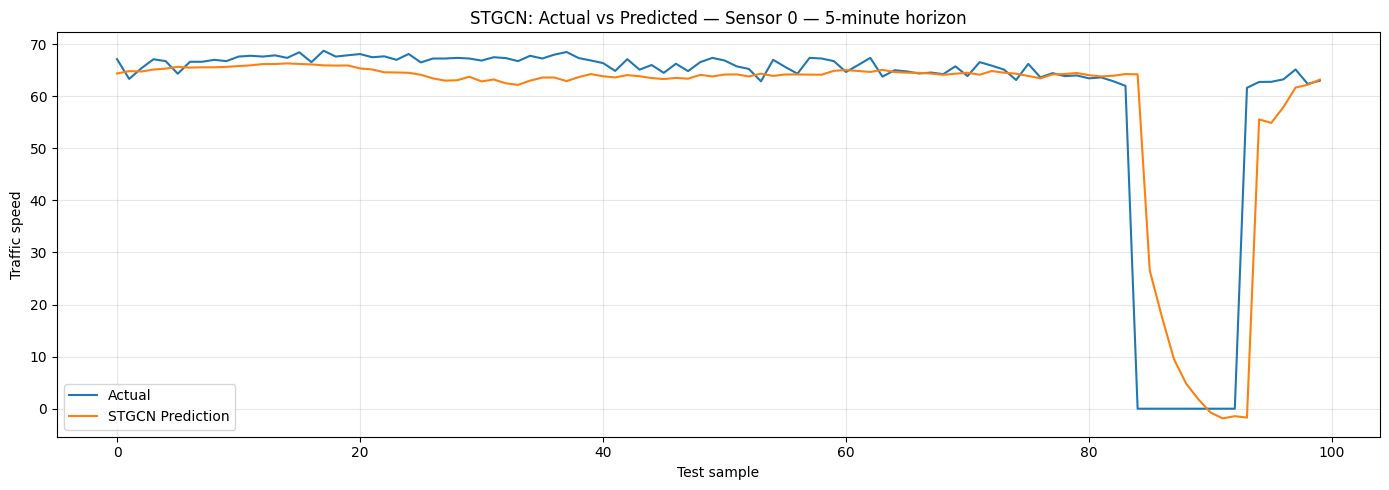

In [17]:
actual_5min = stgcn_true_original[:NUM_SAMPLES_TO_PLOT, 0, SENSOR_INDEX, 0]
predicted_5min = stgcn_pred_original[:NUM_SAMPLES_TO_PLOT, 0, SENSOR_INDEX, 0]

plt.figure(figsize=(14, 5))

plt.plot(actual_5min, label="Actual")
plt.plot(predicted_5min, label="STGCN Prediction")

plt.xlabel("Test sample")
plt.ylabel("Traffic speed")
plt.title(f"STGCN: Actual vs Predicted — Sensor {SENSOR_INDEX} — 5-minute horizon")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

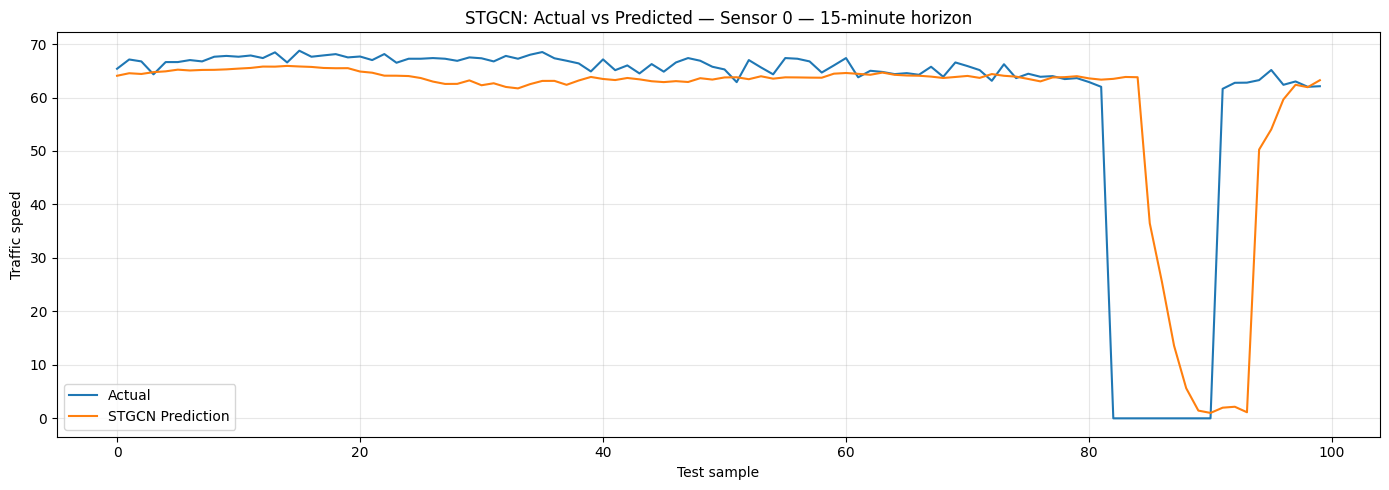

In [18]:
actual_15min = stgcn_true_original[:NUM_SAMPLES_TO_PLOT, 2, SENSOR_INDEX, 0]
predicted_15min = stgcn_pred_original[:NUM_SAMPLES_TO_PLOT, 2, SENSOR_INDEX, 0]

plt.figure(figsize=(14, 5))

plt.plot(actual_15min, label="Actual")
plt.plot(predicted_15min, label="STGCN Prediction")

plt.xlabel("Test sample")
plt.ylabel("Traffic speed")
plt.title(f"STGCN: Actual vs Predicted — Sensor {SENSOR_INDEX} — 15-minute horizon")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [19]:
sensor_mae = np.mean(
    np.abs(stgcn_true_original - stgcn_pred_original),
    axis=(0, 1, 3)
)

print("Sensor MAE shape:", sensor_mae.shape)
print("Number of sensors:", len(sensor_mae))

print("\nBest 10 sensors:")
print(np.argsort(sensor_mae)[:10])

print("\nHighest-error 10 sensors:")
print(np.argsort(sensor_mae)[-10:])

Sensor MAE shape: (207,)
Number of sensors: 207

Best 10 sensors:
[203  45 153 107  92 183  44 202 200   7]

Highest-error 10 sensors:
[ 70 160 105  12  75  47  71  82  38  77]


In [20]:
sensor_results = pd.DataFrame({
    "sensor_index": np.arange(207),
    "MAE": sensor_mae
})

sensor_results = sensor_results.sort_values(
    "MAE",
    ascending=False
).reset_index(drop=True)

sensor_results.head(10)

,sensor_index,MAE
0,77,15.955883
1,38,14.778849
2,82,13.959239
3,71,13.260206
4,47,12.985385
5,75,12.863903
6,12,12.751569
7,105,12.471077
8,160,12.268148
9,70,11.833569


In [21]:
print("Sensor-level MAE statistics")
print(sensor_results["MAE"].describe())

Sensor-level MAE statistics
count    207.000000
mean       6.263304
std        2.506634
min        2.638474
25%        4.497455
50%        5.585657
75%        7.557462
max       15.955883
Name: MAE, dtype: float64


In [22]:
sensor_results.to_csv(
    EVALUATION_DIR / "sensor_mae.csv",
    index=False
)

print("Saved:", EVALUATION_DIR / "sensor_mae.csv")

Saved: /content/experiments/stgcn/sensor_mae.csv


In [23]:
sensor_results["MAE"].describe()

,MAE
count,207.000000
mean,6.263304
std,2.506634
min,2.638474
25%,4.497455
50%,5.585657
75%,7.557462
max,15.955883


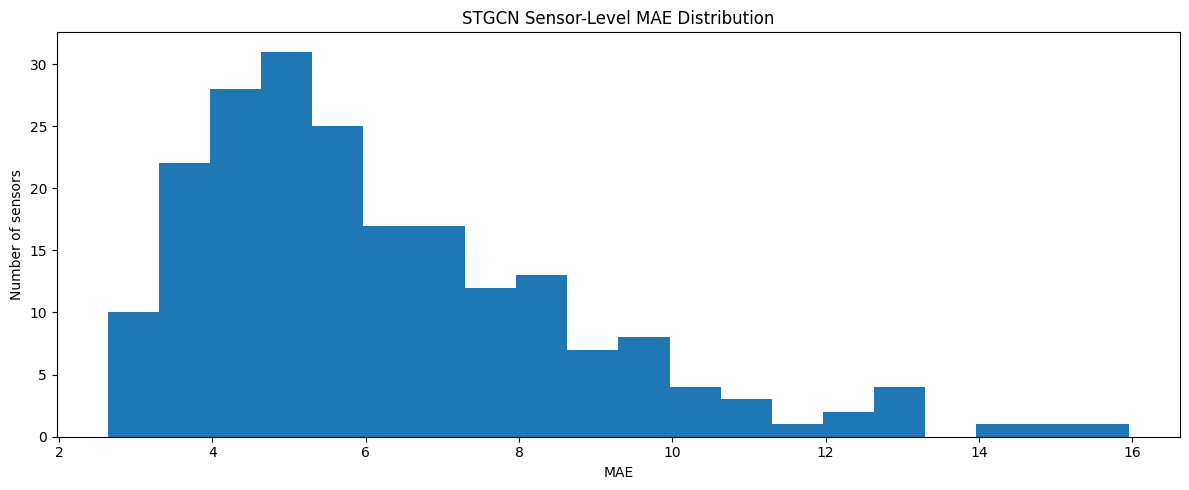

In [24]:
plt.figure(figsize=(12, 5))

plt.hist(sensor_mae, bins=20)

plt.xlabel("MAE")
plt.ylabel("Number of sensors")
plt.title("STGCN Sensor-Level MAE Distribution")

plt.tight_layout()
plt.show()

In [25]:
best_sensor = int(np.argmin(sensor_mae))
worst_sensor = int(np.argmax(sensor_mae))

print("Best-performing sensor:", best_sensor)
print("Best sensor MAE:", sensor_mae[best_sensor])

print("Worst-performing sensor:", worst_sensor)
print("Worst sensor MAE:", sensor_mae[worst_sensor])

Best-performing sensor: 203
Best sensor MAE: 2.6384737
Worst-performing sensor: 77
Worst sensor MAE: 15.955883


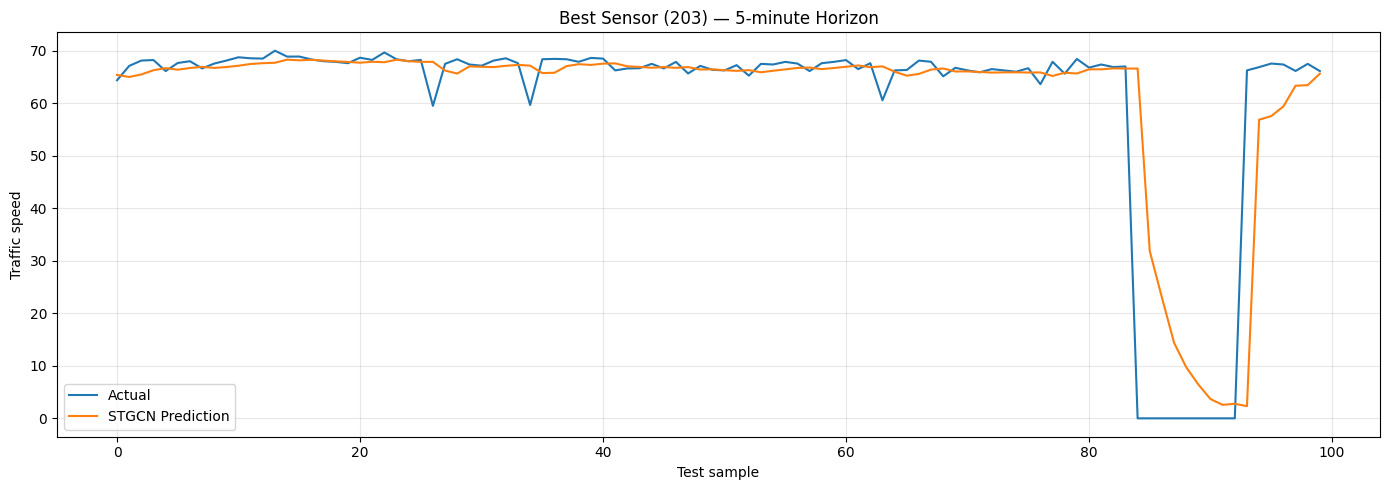

In [26]:
sample_count = 100

best_actual = stgcn_true_original[:sample_count, 0, best_sensor, 0]
best_predicted = stgcn_pred_original[:sample_count, 0, best_sensor, 0]

plt.figure(figsize=(14, 5))

plt.plot(best_actual, label="Actual")
plt.plot(best_predicted, label="STGCN Prediction")

plt.xlabel("Test sample")
plt.ylabel("Traffic speed")
plt.title(f"Best Sensor ({best_sensor}) — 5-minute Horizon")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

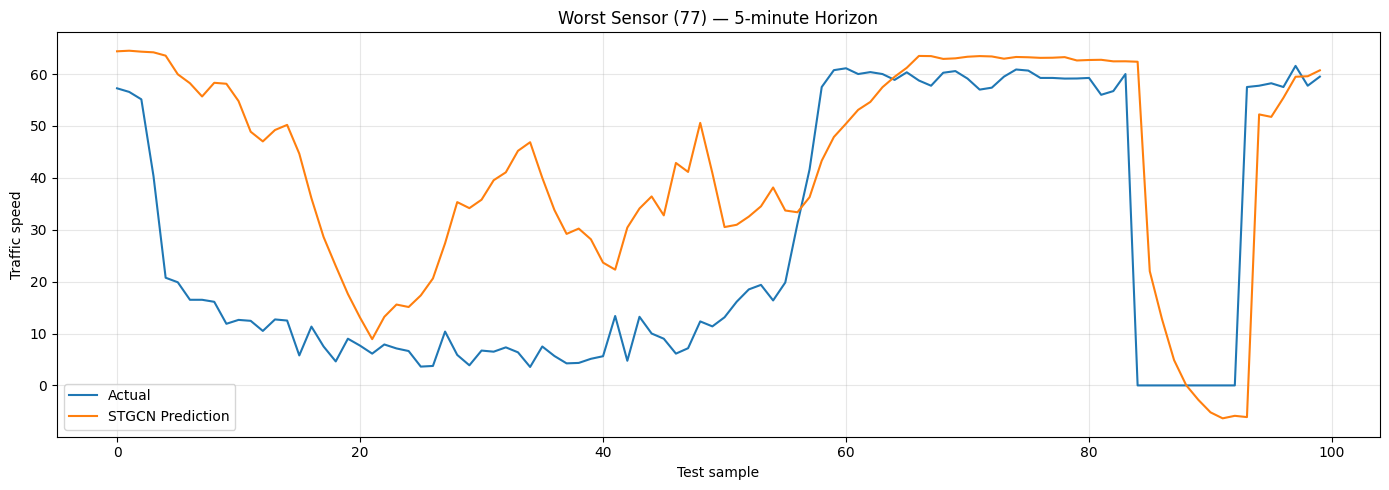

In [27]:
worst_actual = stgcn_true_original[:sample_count, 0, worst_sensor, 0]
worst_predicted = stgcn_pred_original[:sample_count, 0, worst_sensor, 0]

plt.figure(figsize=(14, 5))

plt.plot(worst_actual, label="Actual")
plt.plot(worst_predicted, label="STGCN Prediction")

plt.xlabel("Test sample")
plt.ylabel("Traffic speed")
plt.title(f"Worst Sensor ({worst_sensor}) — 5-minute Horizon")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [28]:
overall_results_df = pd.DataFrame([{
    "Model": "STGCN",
    "MAE": stgcn_original_results["MAE"],
    "RMSE": stgcn_original_results["RMSE"],
    "MAPE": stgcn_original_results["MAPE"],
}])

overall_results_df

,Model,MAE,RMSE,MAPE
0,STGCN,6.263297,11.017338,13.161572


In [29]:
horizon_df

,Horizon,MAE,RMSE,MAPE
0,5 min,5.875838,10.208804,12.432792
1,10 min,6.270047,11.027397,13.169551
2,15 min,6.644026,11.761041,13.882375


In [30]:
overall_results_df.to_csv(
    EVALUATION_DIR / "overall_results.csv",
    index=False
)

horizon_df.to_csv(
    EVALUATION_DIR / "horizon_results.csv",
    index=False
)

sensor_results.to_csv(
    EVALUATION_DIR / "sensor_mae.csv",
    index=False
)

print("Evaluation artifacts saved.")

Evaluation artifacts saved.


In [31]:
FIGURES_DIR = EVALUATION_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Figures directory:", FIGURES_DIR)

Figures directory: /content/experiments/stgcn/figures


In [32]:
plt.savefig(
    FIGURES_DIR / "filename.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

In [33]:
print("STGCN evaluation artifacts:\n")

for path in sorted(EVALUATION_DIR.rglob("*")):
    if path.is_file():
        print(path.relative_to(EVALUATION_DIR))

STGCN evaluation artifacts:

figures/filename.png
horizon_results.csv
overall_results.csv
sensor_mae.csv
test_predictions.npy
test_targets.npy


In [34]:
from pathlib import Path
import shutil

EVALUATION_DIR = Path("/content/experiments/stgcn")
DRIVE_EVALUATION_DIR = Path(
    "/content/drive/MyDrive/urbanAi/experiments/stgcn"
)

DRIVE_EVALUATION_DIR.parent.mkdir(parents=True, exist_ok=True)

if DRIVE_EVALUATION_DIR.exists():
    shutil.rmtree(DRIVE_EVALUATION_DIR)

shutil.copytree(EVALUATION_DIR, DRIVE_EVALUATION_DIR)

print("STGCN evaluation backed up to Google Drive.")
print(DRIVE_EVALUATION_DIR)

print("\nSaved artifacts:")
for path in sorted(EVALUATION_DIR.rglob("*")):
    if path.is_file():
        print(" ", path.relative_to(EVALUATION_DIR))

STGCN evaluation backed up to Google Drive.
/content/drive/MyDrive/urbanAi/experiments/stgcn

Saved artifacts:
  figures/filename.png
  horizon_results.csv
  overall_results.csv
  sensor_mae.csv
  test_predictions.npy
  test_targets.npy
